✅ TASK 3: Car Price Prediction Using Machine Learning

 Use car-related features such as brand value, mileage, engine power, and fuel type.

 Build a regression-based machine learning model to predict car prices.

 Perform data preprocessing, feature engineering, and model evaluation.

 Use Pandas, Scikit-learn, and Matplotlib for the complete workflow.

 Understand real-world applications of price prediction models.




In [142]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

In [143]:
# data ingestion

data = pd.read_csv('/content/cardekho.csv')

Basic Data Understanding

In [144]:
# first five rows of data

data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [145]:
# shape

shape = data.shape
print(f" number of rows and columns in data is {shape}")

 number of rows and columns in data is (8128, 12)


In [146]:
# to check whether null values are present or not

no_null_values = data.isnull().sum()
print(f" the total no of null values present in the data is\n {no_null_values}")

 the total no of null values present in the data is
 name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64


In [147]:
#  to check data has duplicates values or not

no_duplicates = data.duplicated().sum()
print(f" the total no of duplicate values present in data is {no_duplicates}")

 the total no of duplicate values present in data is 1202


In [148]:
# to see the data type

data_type = data.dtypes
print(f" the data type of each column in data is:\n{data_type}")

 the data type of each column in data is:
name                   object
year                    int64
selling_price           int64
km_driven               int64
fuel                   object
seller_type            object
transmission           object
owner                  object
mileage(km/ltr/kg)    float64
engine                float64
max_power              object
seats                 float64
dtype: object


In [149]:
# statistics of data

data.describe()


,year,selling_price,km_driven,mileage(km/ltr/kg),engine,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000,7907.000000,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,19.418783,1458.625016,5.416719
std,4.044249,8.062534e+05,5.655055e+04,4.037145,503.916303,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,16.780000,1197.000000,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,19.300000,1248.000000,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,22.320000,1582.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,14.000000


In [150]:
# see the columns of data

data.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power',
       'seats'],
      dtype='object')

In [151]:
data = data.rename(columns={"mileage(km/ltr/kg)": "mileage"})

## EDA

In [152]:
# see the unique values of fuel columns

data['fuel'].unique()

array(['Diesel', 'Petrol', 'LPG', 'CNG'], dtype=object)

In [153]:
# see the unique values of seller type columns

data['seller_type'].unique()

array(['Individual', 'Dealer', 'Trustmark Dealer'], dtype=object)

In [154]:
# see the unique values of transmission column

data['transmission'].unique()

array(['Manual', 'Automatic'], dtype=object)

In [155]:
#  see the unique values of owner column

data['owner'].unique()

array(['First Owner', 'Second Owner', 'Third Owner',
       'Fourth & Above Owner', 'Test Drive Car'], dtype=object)

In [156]:
#  max power is numeric >> but data type is object >> nan makes it object

data['max_power'].unique()

array(['74', '103.52', '78', '90', '88.2', '81.86', '57.5', '37', '67.1',
       '68.1', '108.45', '60', '73.9', nan, '67', '82', '88.5', '46.3',
       '88.73', '64.1', '98.6', '88.8', '83.81', '83.1', '47.3', '73.8',
       '34.2', '35', '81.83', '40.3', '121.3', '138.03', '160.77',
       '117.3', '116.3', '83.14', '67.05', '168.5', '100', '120.7',
       '98.63', '175.56', '103.25', '171.5', '100.6', '174.33', '187.74',
       '170', '78.9', '88.76', '86.8', '108.495', '108.62', '93.7',
       '103.6', '98.59', '189', '67.04', '68.05', '58.2', '82.85', '81.8',
       '73', '120', '94.68', '160', '65', '155', '69.01', '126.32',
       '138.1', '83.8', '126.2', '98.96', '62.1', '86.7', '188', '214.56',
       '177', '280', '148.31', '254.79', '190', '177.46', '204', '141',
       '117.6', '241.4', '282', '150', '147.5', '108.5', '103.5', '183',
       '181.04', '157.7', '164.7', '91.1', '400', '68', '75', '85.8',
       '87.2', '53', '118', '103.2', '83', '84', '58.16', '147.94',
   

In [157]:
data['max_power'] = pd.to_numeric(data['max_power'], errors='coerce')

# check dtype of max power
data['max_power'].dtype

dtype('float64')

columns : - " 'fuel', 'seller_type',
       'transmission', 'owner' are object , encoding will perform

In [158]:
# value counts for object column

for col in ['fuel', 'seller_type', 'transmission', 'owner']:
    print(data[col].value_counts(normalize=True)*100)
    print()

fuel
Diesel    54.158465
Petrol    44.672736
CNG        0.701280
LPG        0.467520
Name: proportion, dtype: float64

seller_type
Individual          83.243110
Dealer              13.853346
Trustmark Dealer     2.903543
Name: proportion, dtype: float64

transmission
Manual       87.081693
Automatic    12.918307
Name: proportion, dtype: float64

owner
First Owner             65.071358
Second Owner            25.898130
Third Owner              6.828248
Fourth & Above Owner     2.140748
Test Drive Car           0.061516
Name: proportion, dtype: float64



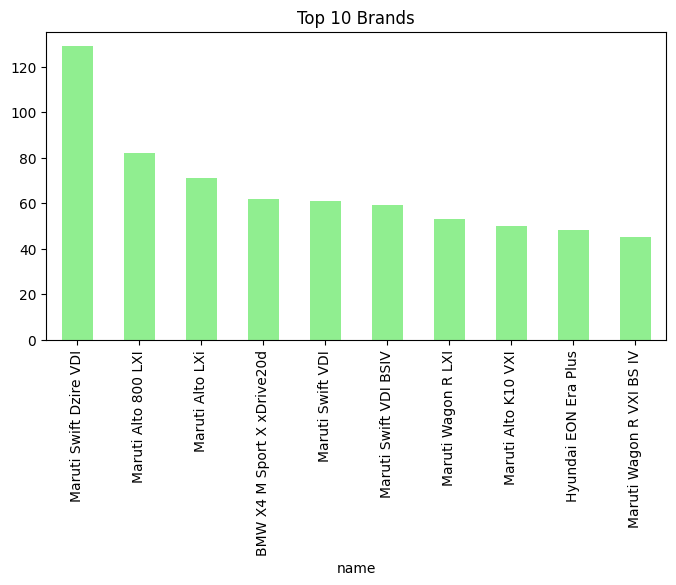

In [159]:
# Top 10 brands car

plt.figure(figsize=(8, 4))
data["name"].value_counts().head(10).plot(kind="bar",color = 'lightgreen')
plt.title("Top 10 Brands")
plt.show()

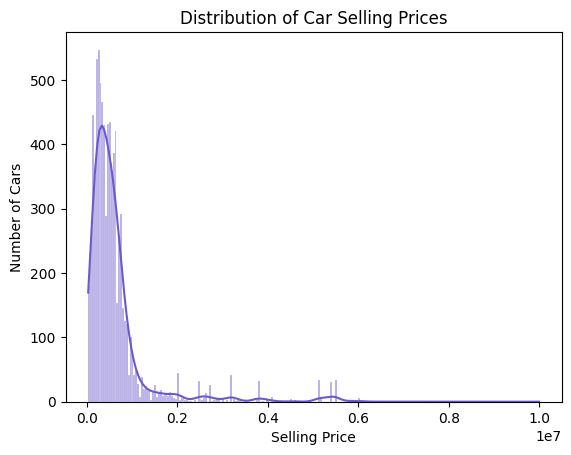

In [160]:
# hist plot

sns.histplot(data=data,x='selling_price',kde=True,color='slateblue',edgecolor='white')

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.show()

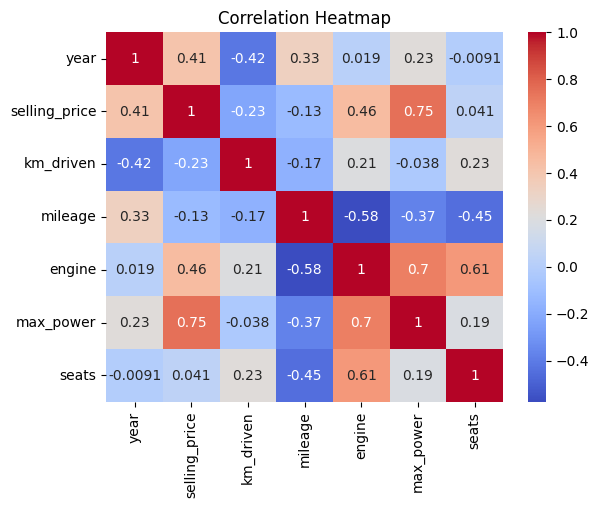

In [161]:
# corellation

sns.heatmap(data.corr(numeric_only = True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

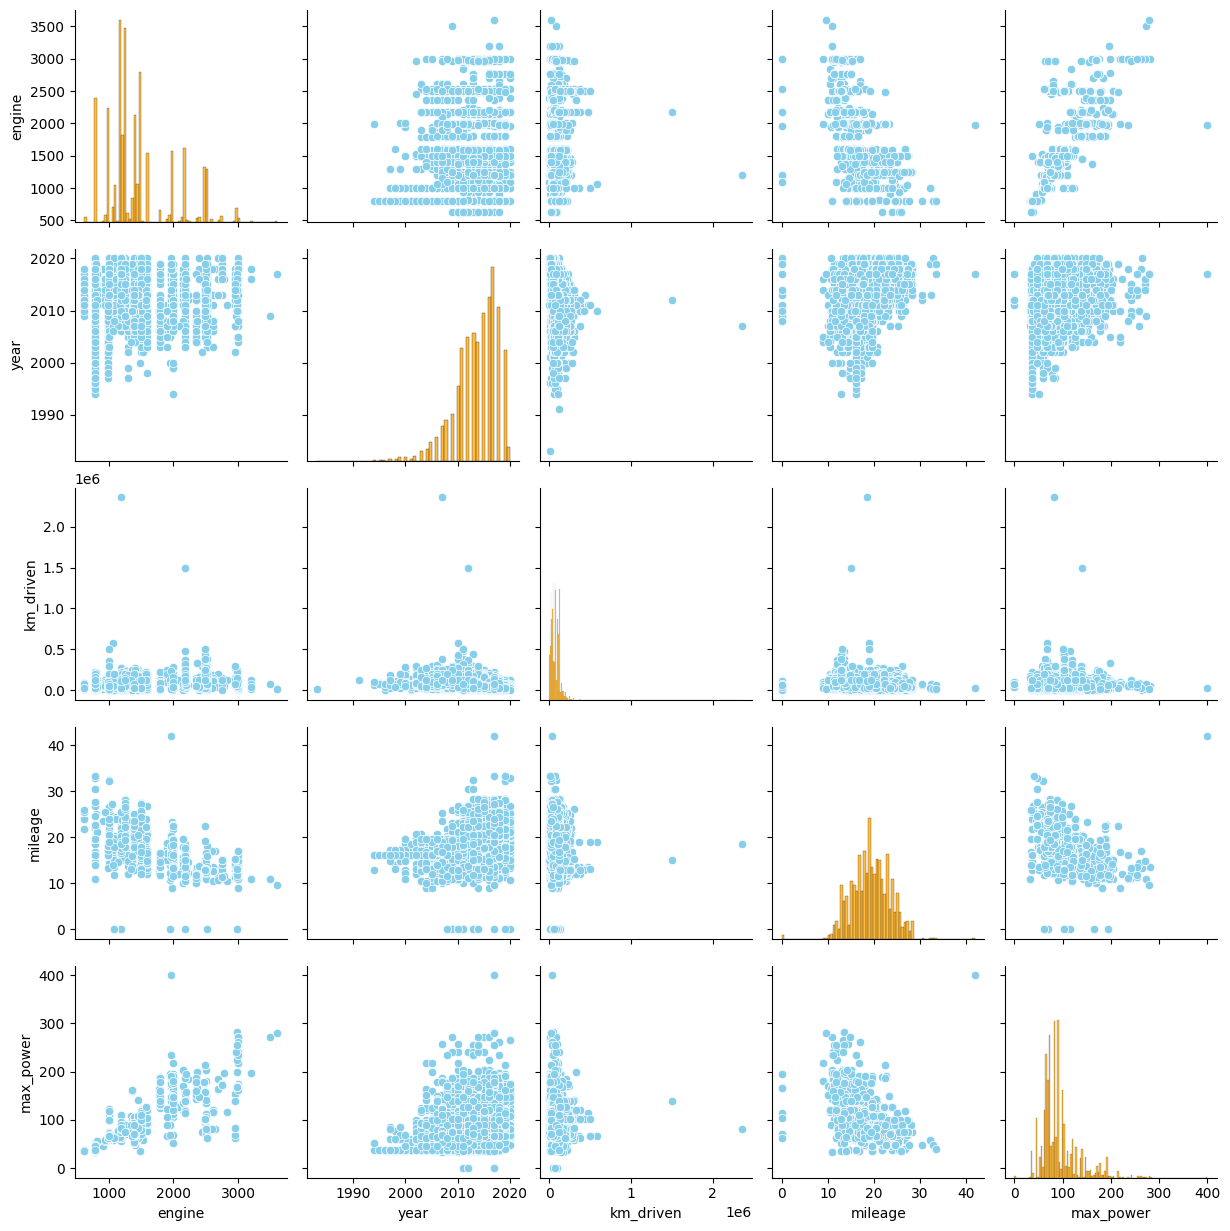

In [162]:
# pair plot

sns.pairplot(
    data[['engine', 'year', 'km_driven','mileage', 'max_power']],
    plot_kws={'color': 'skyblue'},diag_kws={'color': 'orange'})
plt.show()

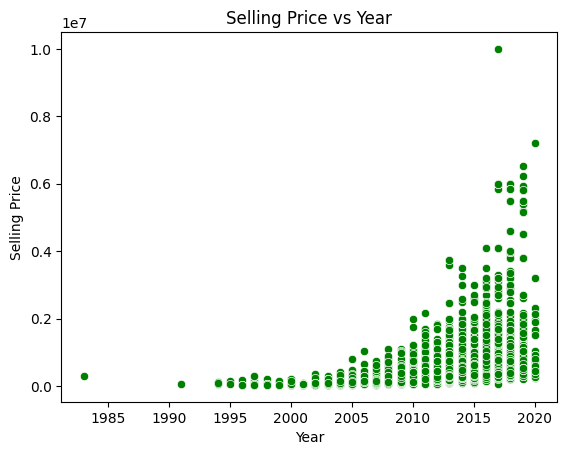

In [163]:
# scatter plot between selling price and year

sns.scatterplot(data=data, x='year',y='selling_price',color = 'green')
plt.title("Selling Price vs Year")
plt.xlabel("Year")
plt.ylabel("Selling Price")
plt.show()

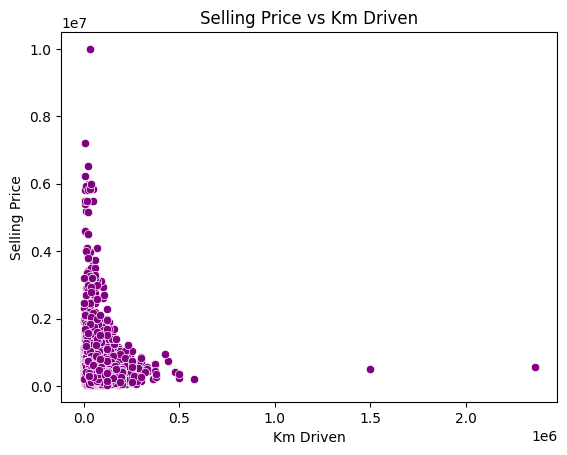

In [164]:
# scatter plot between selling price and km_driven

sns.scatterplot(data=data, x='km_driven',y='selling_price', color = 'purple')
plt.title("Selling Price vs Km Driven")
plt.xlabel("Km Driven")
plt.ylabel("Selling Price")
plt.show()

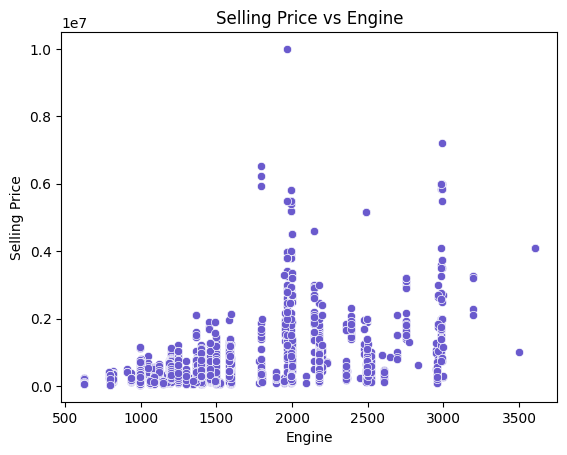

In [165]:
# scatterplot between engine and selling price

sns.scatterplot(data=data, x='engine', y='selling_price' ,color = 'slateblue')
plt.title("Selling Price vs Engine")
plt.xlabel("Engine")
plt.ylabel("Selling Price")
plt.show()

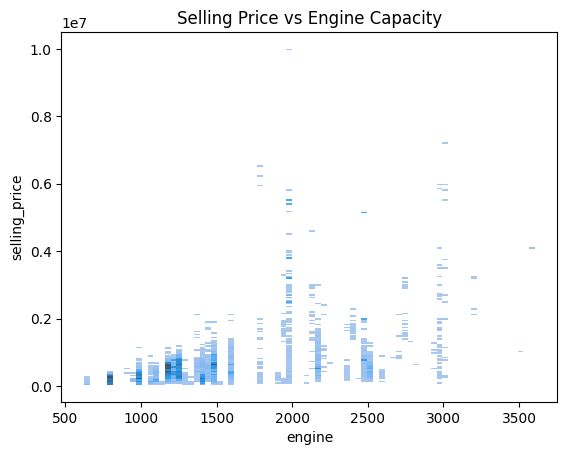

In [166]:
# Using Seaborn lineplot instead of the non-existent plt.line

sns.histplot(data=data, x='engine', y='selling_price')
plt.title('Selling Price vs Engine Capacity')
plt.show()

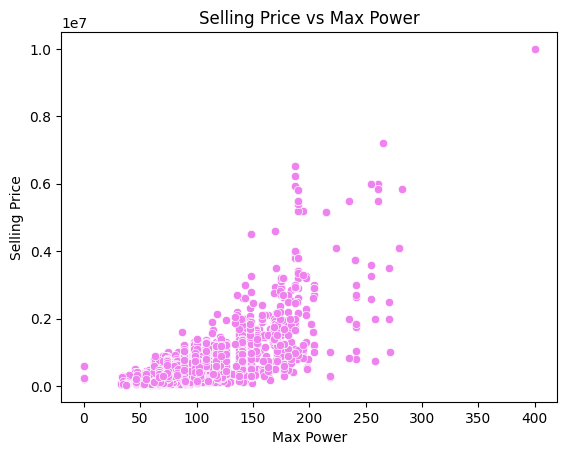

In [167]:
# scatter plot between selling price and max power

sns.scatterplot(data=data, x='max_power',y='selling_price',color = 'violet')
plt.title("Selling Price vs Max Power")
plt.xlabel("Max Power")
plt.ylabel("Selling Price")
plt.show()

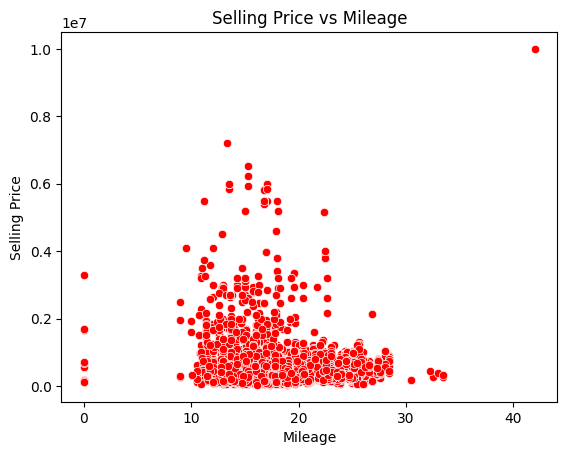

In [168]:
# scatter plot between selling price and mileage)

sns.scatterplot(data=data, x='mileage',y='selling_price',color = 'red')
plt.title("Selling Price vs Mileage")
plt.xlabel("Mileage")
plt.ylabel("Selling Price")
plt.show()

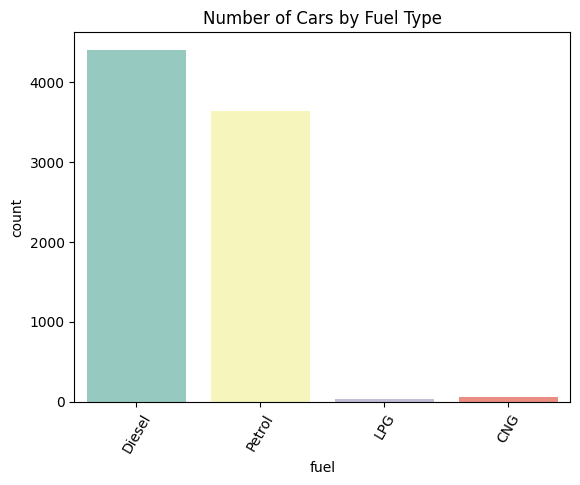

In [169]:
# count plot of fuel

sns.countplot(data=data, x='fuel', palette= 'Set3')
plt.title('Number of Cars by Fuel Type')
plt.xticks(rotation = 60)
plt.show()

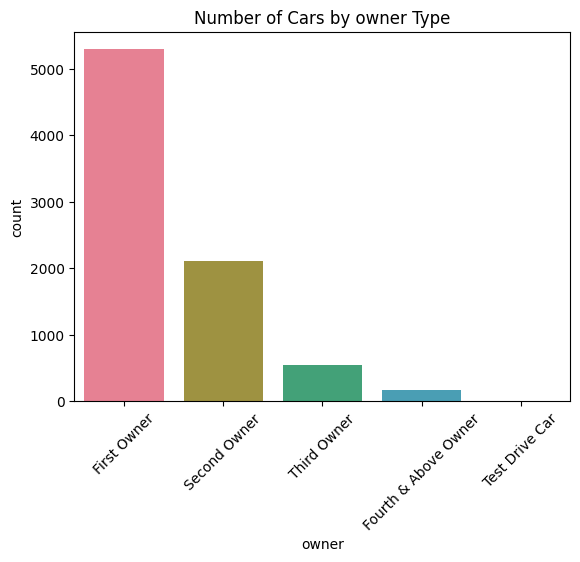

In [170]:
# count plot of owner

sns.countplot(data=data, x='owner', palette= 'husl')
plt.title('Number of Cars by owner Type')
plt.xticks(rotation = 45)
plt.show()


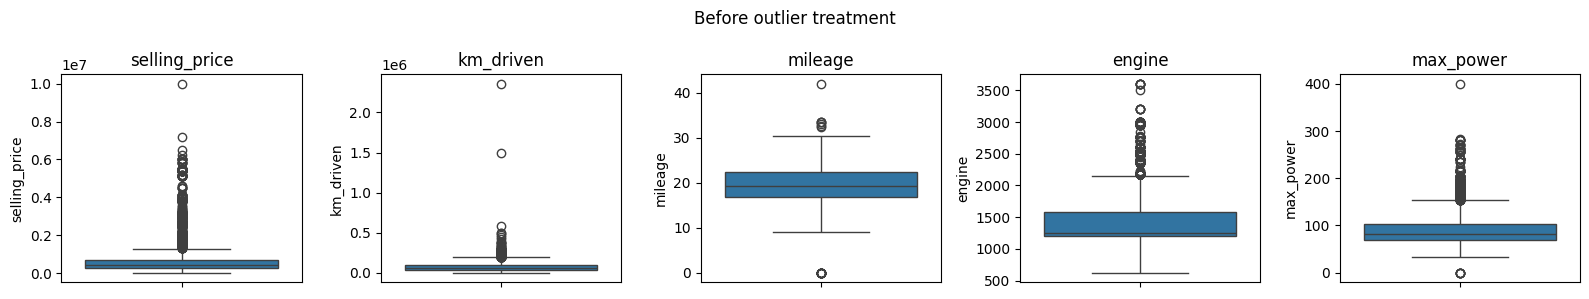

In [171]:
out_cols = ["selling_price", "km_driven", "mileage", "engine", "max_power"]

# Boxplots BEFORE treatment
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, col in zip(axes, out_cols):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Before outlier treatment")
plt.tight_layout()
plt.show()

In [172]:
# checking outliers

num_features = data.select_dtypes(include = 'number')

q1 = num_features.quantile(0.25)
q3 = num_features.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = ((num_features < lower_bound) | (num_features > upper_bound))
print('the number of outliers in each column is')
print(outliers.sum())

the number of outliers in each column is
year               81
selling_price     600
km_driven         170
mileage            24
engine           1183
max_power         570
seats            1653
dtype: int64


In [173]:
# year

data['year'].value_counts().sort_index()

,count
year,
1983,1
1991,1
1994,3
1995,2
1996,3
1997,11
1998,10
1999,18
2000,22


In [174]:
# checking if year data are valid or not for year < 2000

data.loc[data['year'] < 2000,['name', 'year', 'selling_price']].sort_values('year')

,name,year,selling_price
316,Mahindra Willys CJ 3B 4X4,1983,300000
5322,Maruti Omni LPG STD BSIV,1991,55000
1474,Maruti 800 AC,1994,45000
1432,Mahindra Jeep CL 500 MDI,1994,120000
4712,Ambassador Classic 2000 DSZ AC PS,1994,99000
1815,Mahindra Jeep MM 540,1995,160000
3890,Maruti 800 Std,1995,55000
1216,Mahindra Jeep Classic,1996,163000
4108,Maruti 800 DX,1996,40000
6933,Maruti 800 AC,1996,42000


In [175]:
# selling price >> upper bound is 13,05,001

q1 = data['selling_price'].quantile(0.25)
q3 = data['selling_price'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("lower bound : " , lower_bound)
print("upper bound : ", upper_bound)

lower bound :  -375002.5
upper bound :  1305001.5


In [176]:
# >> luxury cars can be expensive, data can be real

data.nlargest(10, 'selling_price')[['name', 'year',  'selling_price']]

,name,year,selling_price
170,Volvo XC90 T8 Excellence BSIV,2017,10000000
2938,BMW X7 xDrive 30d DPE,2020,7200000
4952,Audi A6 35 TFSI Matrix,2019,6523000
4950,Audi A6 35 TFSI Matrix,2019,6223000
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000
1071,BMW 6 Series GT 630d Luxury Line,2018,6000000
4101,BMW 6 Series GT 630d Luxury Line,2018,6000000
4766,BMW 6 Series GT 630d Luxury Line,2018,6000000
5258,Mercedes-Benz S-Class S 350 CDI,2017,6000000
7713,Mercedes-Benz S-Class S 350 CDI,2017,6000000


In [177]:
# km_driven > upper bound is 192500

q1 = data['km_driven'].quantile(0.25)
q3 = data['km_driven'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("lower bound : " , lower_bound)
print("upper bound : ", upper_bound)

lower bound :  -59500.0
upper bound :  192500.0


In [178]:
data.nlargest(10, 'km_driven')[['name', 'year', 'km_driven', 'selling_price']]

,name,year,km_driven,selling_price
3486,Hyundai i20 Asta 1.2,2007,2360457,550000
1810,Mahindra XUV500 W6 2WD,2012,1500000,500000
3508,Maruti Wagon R LXI Minor,2010,577414,194000
3641,Maruti Wagon R VXI BS IV,2011,500000,229999
6673,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,500000,350000
5106,Mahindra Scorpio M2DI,2011,475000,400000
5189,Toyota Innova 2.5 VX (Diesel) 7 Seater,2013,440000,750000
5467,Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV,2010,426000,950000
2272,Mahindra Bolero SLE,2010,380000,260000
7102,Toyota Innova 2.5 V Diesel 8-seater,2007,376412,350000


In [179]:
# data km_driven >> index 3486,1810 has extreme high values so drop it

data = data.drop(index=[3486, 1810])

In [180]:
# mileage > upper bound is 30 and lower bound is 8

q1 = data['mileage'].quantile(0.25)
q3 = data['mileage'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("lower bound : " , lower_bound)
print("upper bound : ", upper_bound)

lower bound :  8.470000000000002
upper bound :  30.63


In [181]:
# checking largest values for mileage >>

data.nlargest(5, 'mileage')[['name', 'year',  'selling_price', 'mileage']]


,name,year,selling_price,mileage
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,42.00
35,Maruti Alto 800 CNG LXI Optional,2019,330000,33.44
3908,Maruti Alto 800 CNG LXI,2017,260000,33.44
7543,Maruti Alto 800 CNG LXI Optional,2019,330000,33.44
5815,Maruti Alto 800 LXI CNG,2020,370000,33.00


In [182]:
# graph has lower outlier present

data.nsmallest(5 ,'mileage')[['name', 'year',  'selling_price', 'mileage']]

,name,year,selling_price,mileage
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,0.0
785,Hyundai Santro Xing GL,2009,120000,0.0
1649,Hyundai Santro Xing GL,2008,105000,0.0
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,0.0
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,0.0


In [183]:
#  mileage = 0 are wrong values

data.loc[data["mileage"] == 0, "mileage"] = np.nan

In [184]:
# max_power > upper bound is 152 and lower bound is 17

q1 = data['max_power'].quantile(0.25)
q3 = data['max_power'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("lower bound : " , lower_bound)
print("upper bound : ", upper_bound)

lower bound :  17.124999999999993
upper bound :  152.925


In [185]:

data[data['max_power']< 17][['name','max_power','selling_price']]

,name,max_power,selling_price
575,Maruti Alto K10 LXI,0.0,204999
576,Maruti Alto K10 LXI,0.0,204999
1442,Maruti Swift Dzire VDI Optional,0.0,589000
1443,Maruti Swift Dzire VDI Optional,0.0,589000
2549,Tata Indica Vista Quadrajet LS,0.0,240000
2550,Tata Indica Vista Quadrajet LS,0.0,240000


In [186]:
# # max power can't be zero

data.loc[data["max_power"] == 0, "max_power"] = np.nan

In [187]:
# data real and valid

data[data['max_power']> 152][['name','max_power','selling_price']]

,name,max_power,selling_price
41,Jeep Compass 1.4 Limited Plus BSIV,160.77,2100000
47,Toyota Fortuner 4x4 MT,168.50,1500000
51,Mitsubishi Pajero Sport 4X4,175.56,1090000
55,Toyota Innova Crysta 2.8 ZX AT BSIV,171.50,1650000
57,Audi A6 2.0 TDI Technology,174.33,1750000
...,...,...,...
7967,BMW 3 Series 320d Sedan,181.00,1500000
8023,Hyundai Santa Fe 4x4 AT,194.30,1200000
8052,Honda CR-V 2.4L 4WD AT,158.80,750000
8057,Honda Accord 2.4 A/T,177.60,580000


In [188]:
# engine >>  lowerbound is 619 and upper bound is 2159

Q1 = data['engine'].quantile(0.25)
Q3 = data['engine'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: 619.5
Upper bound: 2159.5


In [189]:
# engine has no lower bound

data[data['engine'] < 619.5][['engine']]


,engine


In [190]:
# The IQR method identified engine capacities above 2,159.5  outliers.
# Since larger engine capacities can be valid for certain vehicles, these values were retained pending
 # validation rather than removed or capped automatically.

len(data[data['engine']> 2159.5][['engine']])


1182

In [191]:
# seats value counts

data['seats'].value_counts().sort_index()

,count
seats,
2.0,2
4.0,133
5.0,6253
6.0,62
7.0,1119
8.0,236
9.0,80
10.0,19
14.0,1


In [192]:
# data are valid hence not remove

data[data['seats'] > 8][['name', 'seats','selling_price']]

,name,seats,selling_price
276,Mahindra Scorpio LX,9.0,404000
604,Tata Sumo CX 10 Str BSIV,10.0,175000
637,Mahindra Bolero 2011-2019 DI - AC BS III,9.0,700000
711,Chevrolet Tavera Neo 3 LT 9 Seats BSIII,9.0,600000
724,Mahindra Bolero 2011-2019 Plus AC,9.0,550000
...,...,...,...
7462,Mahindra Scorpio LX,9.0,550000
7587,Chevrolet Tavera Neo 3 LS 10 Seats BSIII,10.0,620000
7633,Chevrolet Tavera Neo LT-L - 9 seats BSII,9.0,285000
7666,Tata Sumo CX 9 Seater,9.0,150000


In [193]:
# data are valid hence not remove

data[data['seats'] == 2][['name', 'seats','selling_price']]

,name,seats,selling_price
5900,Mahindra Bolero Pik-Up FB 1.7T,2.0,679000
6629,Mahindra Bolero Pik-Up CBC 1.7T,2.0,722000


In [194]:
# data are valid hence not remove

data[data['seats'] == 14][['name', 'seats','selling_price']]

,name,seats,selling_price
4575,Tata Winger Deluxe - Flat Roof (Non-AC),14.0,235000


## Data Cleaning


In [195]:
# drop the duplicat values

data = data.drop_duplicates(keep='first')

#  Check duplicates after removing
print("After dropping duplicates:", data.duplicated().sum())

After dropping duplicates: 0


In [196]:
# check skewness present in num col or not

num_features = data.select_dtypes(include = 'number')
num_features.skew()

,0
year,-1.011611
selling_price,5.571957
km_driven,1.706494
mileage,0.053721
engine,1.216096
max_power,1.712111
seats,1.918829


## FEATURE ENGINEERING

In [197]:
# Brand = first word of car name

data["brand"] = data["name"].str.split().str[0]

# name has too many unique values, year is replaced by car_age
data = data.drop(columns=["name"])


In [198]:
# Get the top 10 most common brands

top_brand = data["brand"].value_counts().head(10).index[:10].tolist()
top_brand

['Maruti',
 'Hyundai',
 'Mahindra',
 'Tata',
 'Honda',
 'Ford',
 'Toyota',
 'Chevrolet',
 'Renault',
 'Volkswagen']

In [199]:
# Group less common brands into "Other"

def group_brand(brand):
    if brand in top_brand:
        return brand
    else:
        return "Other"

# Apply the function
data["brand"] = data["brand"].apply(group_brand)

# Check the results
print(data["brand"].value_counts())

brand
Maruti        2165
Hyundai       1266
Mahindra       722
Tata           647
Other          448
Honda          362
Ford           361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     174
Name: count, dtype: int64


## Train Test Split

In [200]:
from sklearn.model_selection import train_test_split

In [201]:
# Separating features (X) and target variable (y)

x = data.drop(columns=['selling_price'])
y = data['selling_price']

In [202]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)

print(f"shape of x_train is {x_train.shape}")
print(f"shape of x_test is {x_test.shape}")
print(f"shape of y_train is {y_train.shape}")
print(f"shape of y_test is {y_test.shape}")

shape of x_train is (4846, 11)
shape of x_test is (2078, 11)
shape of y_train is (4846,)
shape of y_test is (2078,)


## Preprocessing Pipeline

In [203]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, FunctionTransformer, StandardScaler,OneHotEncoder,OrdinalEncoder)


In [204]:
# Numerical columns

skew_cols = data[['year', 'km_driven','engine','max_power','seats']].columns.tolist()
print('skew_cols :', skew_cols)
print()

other_num_cols = data[['mileage']].columns.tolist()
print('other_num_cols :', other_num_cols)
print()
# Categorical columns
owner_col = data[['owner']].columns.tolist()
print('owner_col :', owner_col)
print()

onehot_cols = data[['brand', 'fuel', 'seller_type', 'transmission']].columns.tolist()
print('onehot_cols :', onehot_cols)
print()

skew_cols : ['year', 'km_driven', 'engine', 'max_power', 'seats']

other_num_cols : ['mileage']

owner_col : ['owner']

onehot_cols : ['brand', 'fuel', 'seller_type', 'transmission']



In [205]:
# Define distinct numerical feature lists

# Pipeline for continuous skewed columns (gets PowerTransformer)
skew_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log_transform', FunctionTransformer(np.log1p,feature_names_out='one-to-one')),
    ('scaler', StandardScaler())
])

# Pipeline for standard numerical columns (skips PowerTransformer to avoid BracketError)
standard_num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Ordinary categorical pipeline
onehot_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Owner pipeline
owner_order = [
    'First Owner',
    'Second Owner',
    'Third Owner',
    'Fourth & Above Owner',
    'Test Drive Car'
]

owner_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[owner_order],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Combine all pipelines
preprocessor = ColumnTransformer([
    ('skew_num', skew_pipeline, skew_cols),
    ('other_num', standard_num_pipeline, other_num_cols),
    ('onehot', onehot_pipeline, onehot_cols),
    ('owner', owner_pipeline, owner_col)
])

preprocessor

ColumnTransformer(transformers=[('skew_num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log_transform',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scaler', StandardScaler())]),
                                 ['year', 'km_driven', 'engine', 'max_power',
                                  'seats']),
                                ('other_num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),...
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['brand', 'fuel', 'seller_type',
                                  'transmission']),
                                ('owner',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OrdinalEncoder(categories=[['First '
                                                                              'Owner',
                                                                              'Second '
                                                                              'Owner',
                                                                              'Third '
                                                                              'Owner',
                                                                              'Fourth '
                                                                              '& '
                                                                              'Above '
                                                                              'Owner',
                                                                              'Test '
                                                                              'Drive '
                                                                              'Car']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1))]),
                                 ['owner'])])

## Model building


In [206]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [207]:
# base model

lr_pipeline = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('regression', LinearRegression())
])

lr_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['year', 'km_driven',
                                                   'engine', 'max_power',
                                                   'seats']),
                                                 ('other_num',
                                                  Pipeline(steps=[('imputer',
                                                                   Si...
                                                  ['brand', 'fuel',
                                                   'seller_type',
                                                   'transmission']),
                                                 ('owner',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(categories=[['First '
                                                                                               'Owner',
                                                                                               'Second '
                                                                                               'Owner',
                                                                                               'Third '
                                                                                               'Owner',
                                                                                               'Fourth '
                                                                                               '& '
                                                                                               'Above '
                                                                                               'Owner',
                                                                                               'Test '
                                                                                               'Drive '
                                                                                               'Car']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['owner'])])),
                ('regression', LinearRegression())])

In [208]:
# Evaluation

from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error

lr_pred = lr_pipeline.predict(x_test)
lr_pred_x_train = lr_pipeline.predict(x_train)

lr_r2_train = r2_score(y_train, lr_pred_x_train)
lr_r2_test = r2_score(y_test, lr_pred)

print("accuracy of lr_r2_score_train",lr_r2_train)
print("accuracy of lr_r2_score_test", lr_r2_test)

mse = mean_squared_error(y_test, lr_pred)
mae = mean_absolute_error(y_test, lr_pred)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)

accuracy of lr_r2_score_train 0.6086781728701942
accuracy of lr_r2_score_test 0.6044429320226795
Mean Squared Error: 117710869652.8036
Mean Absolute Error: 176024.9418330145


In [209]:
# Random forest

rf_pipeline = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor())
])

rf_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['year', 'km_driven',
                                                   'engine', 'max_power',
                                                   'seats']),
                                                 ('other_num',
                                                  Pipeline(steps=[('imputer',
                                                                   Si...
                                                  ['brand', 'fuel',
                                                   'seller_type',
                                                   'transmission']),
                                                 ('owner',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(categories=[['First '
                                                                                               'Owner',
                                                                                               'Second '
                                                                                               'Owner',
                                                                                               'Third '
                                                                                               'Owner',
                                                                                               'Fourth '
                                                                                               '& '
                                                                                               'Above '
                                                                                               'Owner',
                                                                                               'Test '
                                                                                               'Drive '
                                                                                               'Car']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['owner'])])),
                ('model', RandomForestRegressor())])

In [210]:
# Evaluation Random Forest

rf_pred = rf_pipeline.predict(x_test)
rf_pred_x_train = rf_pipeline.predict(x_train)

rf_r2_train = r2_score(y_train, rf_pred_x_train)
rf_r2_test = r2_score(y_test, rf_pred)
print()
print("accuracy of Random forest of r2_score_train",rf_r2_train)
print("accuracy of Random forest of r2_score_test", rf_r2_test)

mse = mean_squared_error(y_test, rf_pred)
mae = mean_absolute_error(y_test, rf_pred)

print("Mean Squared Error:", mse)
print()
print("Mean Absolute Error:", mae)


accuracy of Random forest of r2_score_train 0.9835221427898713
accuracy of Random forest of r2_score_test 0.9149676898416852
Mean Squared Error: 25304129258.78005

Mean Absolute Error: 77192.24049534809


In [211]:
# Gradient Boostin Regressor

gb_pipeline = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor())
])

gb_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['year', 'km_driven',
                                                   'engine', 'max_power',
                                                   'seats']),
                                                 ('other_num',
                                                  Pipeline(steps=[('imputer',
                                                                   Si...
                                                  ['brand', 'fuel',
                                                   'seller_type',
                                                   'transmission']),
                                                 ('owner',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(categories=[['First '
                                                                                               'Owner',
                                                                                               'Second '
                                                                                               'Owner',
                                                                                               'Third '
                                                                                               'Owner',
                                                                                               'Fourth '
                                                                                               '& '
                                                                                               'Above '
                                                                                               'Owner',
                                                                                               'Test '
                                                                                               'Drive '
                                                                                               'Car']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['owner'])])),
                ('model', GradientBoostingRegressor())])

In [212]:
# Evaluation # Gradient Boostin Regressort

gb_pred = gb_pipeline.predict(x_test)
gb_pred_x_train = gb_pipeline.predict(x_train)

gb_r2_train = r2_score(y_train, gb_pred_x_train)
gb_r2_test = r2_score(y_test, gb_pred)
print()
print("accuracy of  Gradient Boostin  of r2_score_train",gb_r2_train)
print("accuracy of  Gradient Boostin of r2_score_test", gb_r2_test)

mse = mean_squared_error(y_test, gb_pred)
mae = mean_absolute_error(y_test, gb_pred)

print("Mean Squared Error:", mse)
print()
print("Mean Absolute Error:", mae)


accuracy of  Gradient Boostin  of r2_score_train 0.9409342536085873
accuracy of  Gradient Boostin of r2_score_test 0.9152795194198523
Mean Squared Error: 25211334226.65682

Mean Absolute Error: 85951.75229667741


>> Is Random Forest overfitting?

 Random Forest training score is 98.35%, while your test score is 92.0
The gap is approximately 6.35 percentage points. This suggests some overfitting, but the test performance remains strong.
that's why random forest choose for hyperparameter

In [213]:

from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42, n_jobs=1))
])

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [10, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': [0.7, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    scoring='r2',
    cv=3,
    random_state=42,
    n_jobs= 1,
    verbose=2
)

random_search.fit(x_train, y_train)




Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END model__max_depth=20, model__max_features=1.0, model__min_samples_leaf=4, model__min_samples_split=5, model__n_estimators=300; total time=   4.3s
[CV] END model__max_depth=20, model__max_features=1.0, model__min_samples_leaf=4, model__min_samples_split=5, model__n_estimators=300; total time=   4.5s
[CV] END model__max_depth=20, model__max_features=1.0, model__min_samples_leaf=4, model__min_samples_split=5, model__n_estimators=300; total time=   3.7s
[CV] END model__max_depth=20, model__max_features=0.7, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=   2.8s
[CV] END model__max_depth=20, model__max_features=0.7, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=   3.3s
[CV] END model__max_depth=20, model__max_features=0.7, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=   3.9s
[CV] END model_

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skew_num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('log_transform',
                                                                                                FunctionTransformer(feature_names_out='one-to-one',
                                                                                                                    func=<ufunc 'log1p'>)),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['year',
                                                                                'km_driven',
                                                                                'engine',
                                                                                'max_power',
                                                                                'seats']),
                                                                              ('other_...
                                                                                                               handle_unknown='use_encoded_value',
                                                                                                               unknown_value=-1))]),
                                                                               ['owner'])])),
                                             ('model',
                                              RandomForestRegressor(n_jobs=1,
                                                                    random_state=42))]),
                   n_iter=15, n_jobs=1,
                   param_distributions={'model__max_depth': [10, 15, 20],
                                        'model__max_features': [0.7, 1.0],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [100, 200, 300]},
                   random_state=42, scoring='r2', verbose=2)

In [214]:
best_model = random_search.best_estimator_

y_pred = best_model.predict(x_test)

print("Train R²:", best_model.score(x_train, y_train))
print("Test R²:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

Train R²: 0.9806290031218667
Test R²: 0.9209261383142127
MAE: 74488.71244378167
MSE: 23530999138.595108


In [215]:
import joblib

joblib.dump(best_model, 'car_price_model.pkl')
print("Model saved successfully!")

Model saved successfully!
